In [1]:
import lsst.afw.math as afwMath
from lsst.afw.math import binImage
import lsst.afw.image as afwImage
from lsst.daf.butler import Butler
from lsst.pipe.tasks.visualizeVisit import VisualizeMosaicExpConfig, VisualizeMosaicExpTask
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm, trange
from photutils.background import Background2D, MedianBackground
from astropy.stats import SigmaClip
from matplotlib.patches import Polygon
from matplotlib.path import Path
from lsst.summit.utils.utils import getCameraFromInstrumentName
from lsst.afw.cameraGeom import FOCAL_PLANE
from matplotlib.path import Path
from photutils.segmentation import detect_sources, detect_threshold
from photutils.utils import circular_footprint
from astropy.convolution import convolve
from photutils.segmentation import make_2dgaussian_kernel
import lsst.summit.utils.plotting as splot

%matplotlib inline 
%matplotlib widget


        Use pytest instead. [astropy.tests.runner]
        Use pytest instead.
        Use pytest instead. [astropy.utils.decorators]
        Use pytest instead.


In [2]:
def colorbar(mappable):
    from mpl_toolkits.axes_grid1 import make_axes_locatable
    import matplotlib.pyplot as plt
    last_axes = plt.gca()
    ax = mappable.axes
    fig = ax.figure
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.05)
    cbar = fig.colorbar(mappable, cax=cax)
    plt.sca(last_axes)
    return cbar

def doStarless(img):
    kernel = make_2dgaussian_kernel(3, size=3)   
    threshold = detect_threshold(img, 5.)
    segment_map = detect_sources(img, threshold, npixels=5)
    footprint = circular_footprint(radius=3)
    dilateMask = segment_map.make_source_mask(footprint=footprint)
    dilateAndSmoothMask = convolve(dilateMask, kernel)

    starlessImg = np.where(dilateAndSmoothMask != 0, np.median(img), img)
    return starlessImg

def fitPlane(image, order=1):
    '''
    Function to fit a 1st order Chebyshev polynomial to a binned image

    Parameters
    ----------
    image : `lsst.afw.image._image.ImageF`
        FFP image
    order : `int`
        Order of polynomial to fit

    Returns
    -------
    bkgdImage : `lsst.afw.image._image.ImageF`
        Chebyshev model of image
    '''
    # Hard code fit parameters for the notebook
    undersampleStyle = "INCREASE_NXNYSAMPLE"
    statsCtrl = afwMath.StatisticsControl()
    statsCtrl.setNanSafe(True)

    statsFlag = afwMath.stringToStatisticsProperty("MEAN")
    statsCtrl.setNumSigmaClip(1)
    statsCtrl.setNumIter(1)

    width = image.getWidth()
    height = image.getHeight()

    bctrl = afwMath.BackgroundControl(width, height, statsCtrl, statsFlag)
    bctrl.setUndersampleStyle(undersampleStyle)

    bkgd = afwMath.makeBackground(image, bctrl)
    bkgd.getStatsImage().variance = afwImage.ImageF(np.sqrt(bkgd.getStatsImage().image.array))

    actrl = afwMath.ApproximateControl(afwMath.ApproximateControl.CHEBYSHEV, order, order, True)
    undersampleStyle = afwMath.stringToUndersampleStyle(undersampleStyle)

    approx = bkgd.getApproximate(actrl, undersampleStyle)
    bkgdImage = approx.getImage()

    return bkgdImage

def polygon_area(vertices):
    x = vertices[:, 0]
    y = vertices[:, 1]
    return 0.5 * np.abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))


def profile_index(result):
    return result["iv"] if is_u_longest else result["iu"]


def profile_values(i_short):
    return np.array([
        result["net_adu"]
        for result in subpoly_results
        if profile_index(result) == i_short and np.isfinite(result["net_adu"])
    ])


def get_neighbors(iv, iu):
    if CONNECTIVITY == 8:
        return [
            (iv + dv, iu + du)
            for dv in (-1, 0, 1)
            for du in (-1, 0, 1)
            if (dv, du) != (0, 0)
        ]
    return [(iv - 1, iu), (iv + 1, iu), (iv, iu - 1), (iv, iu + 1)]


def plot_cells_and_profiles(sb_grid, selected_only, title, threshold_mag):
    fig, axes = plt.subplots(1, 2, figsize=PIXEL_DISPLAY_FIGSIZE)
    cmap_lines = plt.get_cmap("tab10")

    axes[0].imshow(
        image,
        origin="lower",
        cmap="gray",
        vmin=np.nanpercentile(image, IMAGE_VMIN_PERCENTILE),
        vmax=np.nanpercentile(image, IMAGE_VMAX_PERCENTILE),
    )

    for result in subpoly_results:
        if selected_only and id(result) not in valid_ids:
            continue
        short_idx = profile_index(result)
        edge_color = cmap_lines(short_idx % 10) if n_along_short > 1 else "cyan"
        axes[0].add_patch(Polygon(
            result["corners"], closed=True, fill=False,
            edgecolor=edge_color, linewidth=1.5,
        ))
        if np.isfinite(result["sb_net"]):
            cx, cy = result["corners"].mean(axis=0)
            axes[0].text(
                cx, cy, f"{result['sb_net']:.1f}", color="yellow",
                fontsize=7, ha="center", va="center", weight="bold",
            )

    axes[0].set_title(title)

    x_indices = np.arange(n_along_long)
    x_label = f"Indice asse maggiore ({longest_axis_name})"
    for i_short in range(n_along_short):
        line = sb_grid[i_short, :] if is_u_longest else sb_grid[:, i_short]
        if not np.any(np.isfinite(line)):
            continue
        line_color = cmap_lines(i_short % 10) if n_along_short > 1 else "crimson"
        axes[1].plot(
            x_indices, line, "s-", color=line_color,
            label=f"{short_axis_name}={i_short}", linewidth=2, markersize=5,
        )

    if np.isfinite(threshold_mag):
        axes[1].axhline(
            threshold_mag, color="darkorange", linestyle="--", linewidth=2,
            label=f"Global half-max ({threshold_mag:.2f})",
        )
    if np.isfinite(sb_net_poly):
        axes[1].axhline(
            sb_net_poly, color="black", linestyle=":", alpha=0.8,
            label=f"Global Net SB ({sb_net_poly:.2f})",
        )

    axes[1].set_xlabel(x_label)
    axes[1].set_ylabel("Artifact Surface Brightness (mag / arcsec²)")
    axes[1].set_title("Profili 1D con cut half-maximum globale")
    axes[1].grid(True, linestyle=":", alpha=0.6)
    axes[1].invert_yaxis()
    axes[1].legend()
    plt.tight_layout()
    plt.show()



In [3]:
import pandas as pd

# Read the CSV file
visitsl=[]
df_stray = pd.read_csv("../data/raw/stray_light_20260506.csv")
filt = ['u', 'g', 'r', 'i', 'z', 'y']
for f in filt:
    # Filter for band 'u' and rows where the last column contains 'tape'
    # mask_band = df_stray['band'] == f
    # mask_tape = df_stray['artifact'] ='tape'
    filtered = df_stray[(df_stray['band'] == f ) & (df_stray['artifact'] == 'tape') & (df_stray['target_name']== 'Rubin_SV_225_-40')]
    # Get the latest 10 lines (assuming the CSV is sorted by time, or use sort if there's a timestamp column)
    latest_10 = filtered.sample(n=10, random_state=42)
    
    print(f"10 entries for band {f}:")
    print(latest_10['exposure_id'])

    visitsl.append(latest_10['exposure_id'].tolist())

visits = [item for sublist in visitsl for item in sublist]

10 entries for band u:
16483    2025060100662
12551    2025052300325
33933    2025072300056
7805     2025050500473
33911    2025072300034
33913    2025072300036
16485    2025060100664
12558    2025052300332
7797     2025050500465
7787     2025050500455
Name: exposure_id, dtype: int64
10 entries for band g:
19958    2025062200367
22437    2025070300202
11532    2025052100158
16445    2025060100624
22430    2025070300195
33951    2025072300074
19957    2025062200366
33964    2025072300087
20240    2025062300349
12529    2025052300303
Name: exposure_id, dtype: int64
10 entries for band r:
33985    2025072300108
33993    2025072300116
7753     2025050500421
33968    2025072300091
7758     2025050500426
20233    2025062300342
11547    2025052100173
7765     2025050500433
19997    2025062200406
33997    2025072300120
Name: exposure_id, dtype: int64
10 entries for band i:
11574    2025052100200
10896    2025051900386
10918    2025051900408
11575    2025052100201
10914    2025051900404
11349  

In [4]:
# First two are nightlyValidation17, so need to be re-constructed
# Last two are nightlyValidation18, which are still around
# visits = [2025051500395, 2025050500427, 2025051900386, 2025051900400]
# visits=[2025070300600, 2025060100658,2025060300083]
# visits=[latest_10['exposure_id'].iloc[0]]
count=3
visits=[2025072000093, 2026031000208, 2026031200632, 2026042700129]
# visits=[2026010500342, 2026010400334, 2026010500307, 2026010700344, 2026010700407, 2026010400357, 2026010100305, 2026010400339, 2026010500353, 2026010700400]

In [5]:
repo = "main"
# repo = "embargo"
butler = Butler(config=repo,instrument='LSSTCam')

In [6]:
# coll=["u/ataranto/sb_tape"]
# coll=["u/ataranto/mono_flats"]
coll=["u/ataranto/lsst_outputs"]
# coll=["LSSTCam/runs/nightlyValidation"]
# coll=['LSSTCam/raw/all']
# coll=['u/ataranto/SkyCorr/fullSkyCorr']
# coll=['u/ataranto/M2baff_isr']

In [7]:
binning = 8
badMaskNames  = ["NO_DATA", "DETECTED", "DETECTED_NEGATIVE", "SAT", "BAD", "INTRP", "CR",]
# print(count)
print(visits[count])
detects = range(117,190)
bad = [ 122]
pIsrImsBinned = []
ids = []
for i in tqdm(detects):
    dataId = {"instrument": "LSSTCam", "exposure": visits[count], "detector": i}
    if i in bad:
        continue
    else:
        try:
            im = butler.get("post_isr_image", dataId=dataId, collections=coll)

            bad_mask_bit_mask = im.mask.getPlaneBitMask(badMaskNames)
            msk = (im.mask.array.astype(int) & bad_mask_bit_mask) != 0
            im.getMaskedImage().image.array[msk] = np.nan  # Try removing detections &c.
            ids.append(i)
            pIsrImsBinned.append(binImage(im.getMaskedImage(), binning))    #by default this makes a mean bining, 
                                                                            #it does not associate the sum of the pixels to the new superpixel
        except:
            # print(i,'fai')
            continue

2026042700129


100%|██████████| 73/73 [02:54<00:00,  2.40s/it]


In [ ]:
# from astropy.io import fits
# import os
# with fits.open(os.path.join('../rubin-user/M2_BAFFLE/20DEG-OFFAXIS/', "Y-Band-stack20_sum.fits")) as hdul_z:
#     data_z = hdul_z[0].data
    


### USE THIS CELL TO RUN WITH THE REAL ON-SKY IMAGE FROM THE BUTLER ###

Click 4 times on the image to define the corners of your polygon.


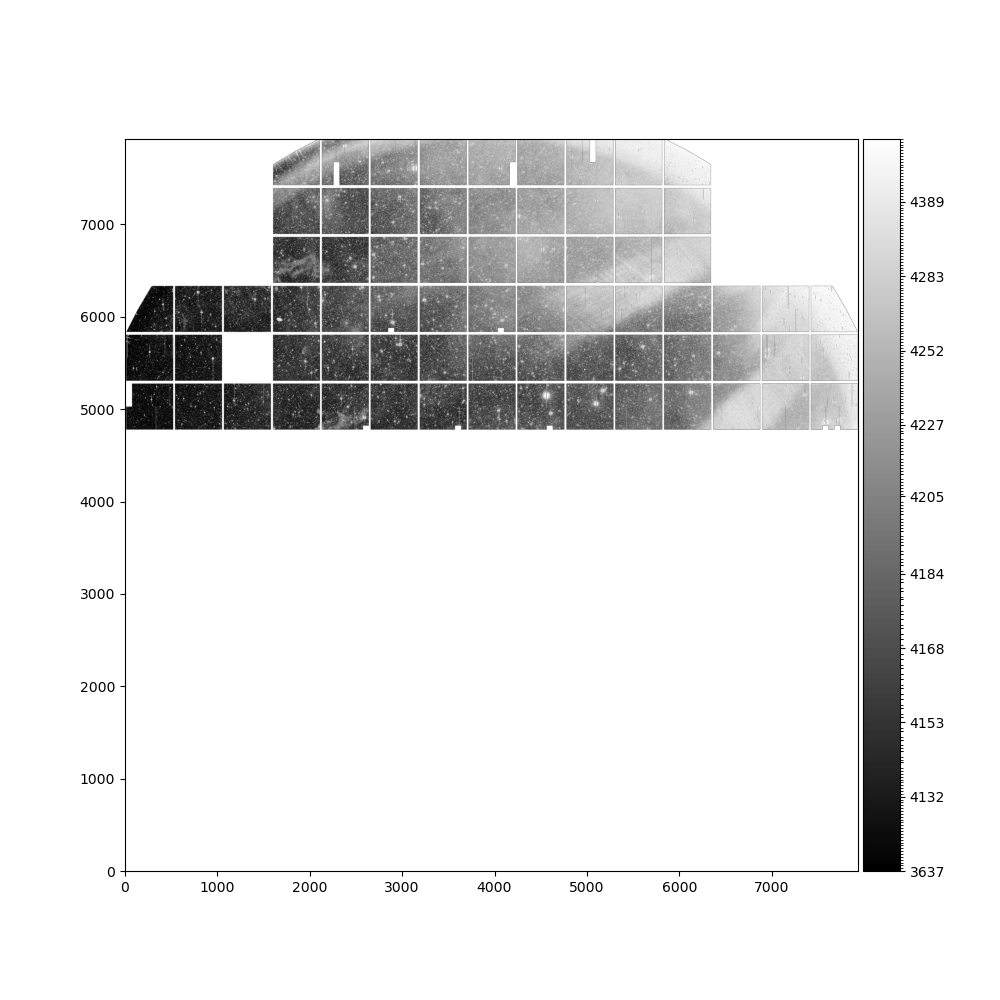

In [8]:
# camera = butler.get("camera", instrument="LSSTCam", collections="LSSTCam/calib/DM-50716/unbounded")
camera = getCameraFromInstrumentName('LSSTCam')
plt.close('all')
mosConfig = VisualizeMosaicExpConfig()
mosConfig.binning = binning
mosTask = VisualizeMosaicExpTask(config=mosConfig)
pIsrMosaic = mosTask.run(pIsrImsBinned, camera, inputIds=ids).outputData
splot.plot(pIsrMosaic.array, stretch='ccs')
# Mask out the vignetted region before fitting
med = np.nanmedian(pIsrMosaic.array)

xCen, yCen = (pIsrMosaic.array.shape[0]/2, pIsrMosaic.array.shape[1]/2)
rad = (pIsrMosaic.array.shape[0] + pIsrMosaic.array.shape[1])/ 4  # Roughly the vignetted region radius
x = np.arange(1, pIsrMosaic.array.shape[1]+1)
y = x.reshape(-1, 1)
r = np.sqrt((x - xCen)**2 + (y - yCen)**2)
vignet = r >= rad

vignet = vignet[1:, :]
clone = pIsrMosaic.clone()
# Ensure vignet matches the shape of clone.array
vignet_mask = vignet
if vignet.shape != clone.array.shape:
	# Adjust vignet to match the shape of clone.array
	min_rows = min(vignet.shape[0], clone.array.shape[0])
	min_cols = min(vignet.shape[1], clone.array.shape[1])
	vignet_mask = vignet[:min_rows, :min_cols]
	clone.array = clone.array[:min_rows, :min_cols]
clone.array[vignet_mask] = np.nan
# First fit, ignoring the vignetted region
bkgd1 = fitPlane(clone, 3)

sigma_clip = SigmaClip(sigma=3.0)
bkg_estimator = MedianBackground()
bkgd = Background2D(clone.array, (200, 200), filter_size=(3, 3), sigma_clip=sigma_clip, bkg_estimator=bkg_estimator)
# Now mask out bright residual peaks and fit again
want = (pIsrMosaic.array - bkgd1.array) >= 5
clone.array[want] = np.nan
# bkgd = fitPlane(clone, 5)

# fig, ax = plt.subplots(1, 3, figsize=(15, 5))
# ax[0].imshow(pIsrMosaic.array, origin="lower", vmin=med-20, vmax=med+30)
# ax[1].imshow(bkgd.array, origin="lower")
# cb = ax[2].imshow(pIsrMosaic.array - bkgd.array, vmin=-100, vmax=70, origin="lower")
# colorbar(cb)
 
image=pIsrMosaic.array # - bkgd.array
med = np.nanmedian(image)
# plt.close('all')
fig = plt.figure(figsize=(10, 10))
cb = splot.plot(image, stretch='ccs', figure=fig)
ax = fig.axes[0]  # Use the axes created by splot.plot()

polygon_points = []

def onclick(event):
    # Only register clicks inside the axes
    if event.inaxes != ax:
        return
    # Add point
    polygon_points.append((event.xdata, event.ydata))
    # Draw point
    ax.plot(event.xdata, event.ydata, 'ro')
    fig.canvas.draw()
    # If 4 points, draw polygon and disconnect
    if len(polygon_points) == 4:
        poly = Polygon(polygon_points, closed=True, fill=False, edgecolor='yellow', linewidth=2)
        ax.add_patch(poly)
        fig.canvas.draw()
        fig.canvas.mpl_disconnect(cid)
        # Build the mask for use outside the function
        global poly_mask
        poly_path = Path(polygon_points)
        ny, nx = pIsrMosaic.array.shape
        yy, xx = np.mgrid[:ny, :nx]
        coords = np.vstack((xx.ravel(), yy.ravel())).T
        poly_mask = poly_path.contains_points(coords).reshape(ny, nx)

# After you have clicked 4 times and the polygon is drawn, run this in a new cell:



cid = fig.canvas.mpl_connect('button_press_event', onclick)
print("Click 4 times on the image to define the corners of your polygon.")
# plt.close()

In [ ]:
### USE THIS CELL TO RUN WITH CBP STACKED IMAGE ###

In [ ]:
fig = plt.figure(figsize=(10, 10))
cb = plt.imshow(image, cmap='gray', vmin=np.nanpercentile(data_z, 5),
                vmax=np.nanpercentile(data_z, 95), origin='lower')
ax = fig.axes[0]  # Use the axes created by plt.imshow()

polygon_points = []
polygon_artist = None
point_artists = []


def redraw_polygon():
    """Redraw the currently selected polygon vertices and edges."""
    global polygon_artist

    for artist in point_artists:
        artist.remove()
    point_artists.clear()

    if polygon_artist is not None:
        polygon_artist.remove()
        polygon_artist = None

    if polygon_points:
        x_points, y_points = np.array(polygon_points).T
        point_artists.extend(ax.plot(x_points, y_points, 'ro'))
        if len(polygon_points) >= 2:
            polygon_artist = Polygon(
                polygon_points,
                closed=False,
                fill=False,
                edgecolor='yellow',
                linewidth=2,
            )
            ax.add_patch(polygon_artist)

    fig.canvas.draw_idle()


def onclick(event):
    if event.inaxes != ax or event.xdata is None or event.ydata is None:
        return
    polygon_points.append((event.xdata, event.ydata))
    redraw_polygon()


def onkey(event):
    global poly_mask, polygon_artist

    if event.key in ('enter', 'return'):
        if len(polygon_points) < 3:
            print("Servono almeno 3 punti per chiudere il poligono.")
            return

        polygon_artist = Polygon(
            polygon_points,
            closed=True,
            fill=False,
            edgecolor='yellow',
            linewidth=2,
        )
        ax.add_patch(polygon_artist)
        poly_path = Path(polygon_points)
        ny, nx = image.shape
        yy, xx = np.mgrid[:ny, :nx]
        coords = np.vstack((xx.ravel(), yy.ravel())).T
        poly_mask = poly_path.contains_points(coords).reshape(ny, nx)
        fig.canvas.mpl_disconnect(cid)
        fig.canvas.mpl_disconnect(key_cid)
        fig.canvas.draw_idle()
        print(f"Poligono confermato con {len(polygon_points)} punti.")

    elif event.key == 'escape':
        polygon_points.clear()
        redraw_polygon()
        print("Selezione annullata.")


cid = fig.canvas.mpl_connect('button_press_event', onclick)
key_cid = fig.canvas.mpl_connect('key_press_event', onkey)
print("Clicca per aggiungere i vertici; premi Enter/Invio per chiudere il poligono.")
print("Premi Esc per annullare la selezione.")

In [9]:

detector_corners = {}
for det in camera:
    # Get detector corners in focal plane coordinates
    corners = det.getCorners(FOCAL_PLANE)
    # Convert to numpy array for easier plotting
    corners_fp_arr = np.array([[pt.getX(), pt.getY()] for pt in corners])
    detector_corners[det.getId()] = corners_fp_arr
# Convert polygon points to numpy array and to mm (assuming 1 unit = 1 pixel, and LSST pixel size is 0.01 mm)
poly_points = np.array(polygon_points)

# Center around (0,0)
poly_points_mm_centered = (poly_points - (image.shape[1]/2) )*(np.abs(np.min(detector_corners[0]))/(image.shape[1]/2))
# print(np.abs(np.min(detector_corners[0])),image.shape[0])
det_ids_in_poly = []
for det_id, corners in detector_corners.items():
   
    det_path = Path(corners)
    poly_path = Path(poly_points_mm_centered)
    min_x, min_y = np.min(poly_points_mm_centered, axis=0)
    max_x, max_y = np.max(poly_points_mm_centered, axis=0)
    grid_x, grid_y = np.meshgrid(
        np.linspace(min_x, max_x, 100),
        np.linspace(min_y, max_y, 100)
    )
    grid_points = np.vstack([grid_x.ravel(), grid_y.ravel()]).T
    inside_poly = poly_path.contains_points(grid_points)
    poly_interior_points = grid_points[inside_poly]
    if np.any(det_path.contains_points(poly_interior_points)):
        det_ids_in_poly.append(det_id)
    

print("Detector IDs where polygon falls:", det_ids_in_poly)

# bgSub = pIsrMosaic.clone()
# bgSub.array -= bkgd.array
# from astropy.io import fits
# fits.writeto("./img_e_data/16binbksub_%d.fits" % (visits[0]), image, overwrite=True)
poly_sum = np.nansum(image[poly_mask])
num_pixels = np.count_nonzero(np.isfinite(image[poly_mask]))   #those are the effectively used pixels without nan, zeros, bad px etc...
# num_pixels= len(image[poly_mask])
print("Number of pixels inside polygon:", num_pixels, " px")
print("Sum inside polygon region:", poly_sum , "ADU")
print("MEDIAN counts accross image:", np.nanmedian(image[poly_mask]), "ADU")
pixel_area_arcsec2 = (0.2*binning)**2
inst_flux = poly_sum / num_pixels   # instrumental flux in counts
# inst_flux= np.nanmedian(image[poly_mask])
# surface_brightness_mag = exp.photoCalib.instFluxToMagnitude(inst_flux) + 2.5 * np.log10(pixel_area_arcsec2)
print("MEAN counts across image (tot ct / tot area px):", inst_flux ," ADU")
# print("Surface brightness:", surface_brightness_mag)
dataId = {'instrument': 'LSSTCam', 'detector': 94, 'visit': visits[3]}

mag = []
for det in det_ids_in_poly:
    if det not in [120,121,122]:
        try:
            dataId['detector'] = det
            exp = butler.get('preliminary_visit_image', dataId=dataId, collections=coll)
            m = exp.photoCalib.instFluxToMagnitude(inst_flux/pixel_area_arcsec2) # + 2.5 * np.log10(pixel_area_arcsec2)
            mag.append(m)
            # print(f"{det}:  SurfaceBr={m:.4f} mag/arcsec^2")
        except:
            print('nocalib')
            continue

mean_mag = np.mean(mag)
print(f"Mean magnitude across detectors: {mean_mag:.4f}")
print(count)
count+=1

Detector IDs where polygon falls: [139, 140, 142, 143, 147, 150, 151, 152, 180, 181, 182, 185]
Number of pixels inside polygon: 1132354  px
Sum inside polygon region: 4.8903393e+09 ADU
MEDIAN counts accross image: 4258.742 ADU
MEAN counts across image (tot ct / tot area px): 4318.737186427566  ADU


/sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.1.0/share/eups/Linux64/obs_base/g00893bd134+caafe9eba2/python/lsst/obs/base/formatters/fitsExposure.py:798: FutureWarning: Summary fields [centroidDiffShapeletsVsSlotMedian, nShapeletsStar, psfAdaptiveIncludeThresholdMultiplier, psfAdaptiveThresholdValue, refCatSourceDensity, shapeletsCoeffs, shapeletsIqScore, shapeletsOnlyIqScore, shapeletsStarEMedian, shapeletsStarUnNormalizedEMedian, starComa1Median, starComa2Median, starE41Median, starE42Median, starKurtosisMedian, starTrefoil1Median, starTrefoil2Median] not recognized by this software version; ignoring them.
  result = self.reader.read(**self.checked_parameters, dtype=self.storageClass_dtype)


Mean magnitude across detectors: 23.5082
3


In [10]:
MIN_CELL_SIZE= 150

# Refresh della geometria: usa sempre la selezione manuale corrente.
selection_corners = np.asarray(polygon_points, dtype=float)
if selection_corners.shape[0] < 3:
    raise ValueError("La selezione deve contenere almeno 3 vertici.")

# La subdivisione usa un quadrilatero orientato secondo gli assi principali
# del poligono, ma viene ricostruito ogni volta dai polygon_points correnti.
selection_centroid = selection_corners.mean(axis=0)
selection_centered = selection_corners - selection_centroid
selection_cov = selection_centered.T @ selection_centered
selection_eigvals, selection_eigvecs = np.linalg.eigh(selection_cov)
selection_order = np.argsort(selection_eigvals)[::-1]
selection_basis = selection_eigvecs[:, selection_order]
selection_projection = selection_centered @ selection_basis

selection_x_min, selection_x_max = selection_projection[:, 0].min(), selection_projection[:, 0].max()
selection_y_min, selection_y_max = selection_projection[:, 1].min(), selection_projection[:, 1].max()

p0 = selection_centroid + np.array([selection_x_min, selection_y_max]) @ selection_basis.T
p1 = selection_centroid + np.array([selection_x_min, selection_y_min]) @ selection_basis.T
p2 = selection_centroid + np.array([selection_x_max, selection_y_min]) @ selection_basis.T
p3 = selection_centroid + np.array([selection_x_max, selection_y_max]) @ selection_basis.T

len_u = np.linalg.norm(p1 - p0)
len_v = np.linalg.norm(p3 - p0)
n_u = max(1, int(len_u // MIN_CELL_SIZE))
n_v = max(1, int(len_v // MIN_CELL_SIZE))

is_u_longest = len_u >= len_v
longest_axis_name = "u" if is_u_longest else "v"
short_axis_name = "v" if is_u_longest else "u"
n_along_long = n_u if is_u_longest else n_v
n_along_short = n_v if is_u_longest else n_u

us = np.linspace(0, 1, n_u + 1)
vs = np.linspace(0, 1, n_v + 1)
grid_pts = np.empty((n_u + 1, n_v + 1, 2))
for iu, u in enumerate(us):
    for iv, v in enumerate(vs):
        grid_pts[iu, iv] = (
            (1 - u) * (1 - v) * p0
            + u * (1 - v) * p1
            + u * v * p2
            + (1 - u) * v * p3
        )

ny, nx = image.shape
yy_full, xx_full = np.mgrid[:ny, :nx]
subpoly_results = []

for iu in range(n_u):
    for iv in range(n_v):
        cell_corners = np.array([
            grid_pts[iu, iv],
            grid_pts[iu + 1, iv],
            grid_pts[iu + 1, iv + 1],
            grid_pts[iu, iv + 1],
        ])
        min_x, min_y = np.floor(cell_corners.min(axis=0)).astype(int)
        max_x, max_y = np.ceil(cell_corners.max(axis=0)).astype(int)
        min_x, min_y = max(min_x, 0), max(min_y, 0)
        max_x, max_y = min(max_x, nx), min(max_y, ny)

        cell_path = Path(cell_corners)
        yy_box, xx_box = yy_full[min_y:max_y, min_x:max_x], xx_full[min_y:max_y, min_x:max_x]
        box_coords = np.vstack((xx_box.ravel(), yy_box.ravel())).T
        inside = cell_path.contains_points(box_coords).reshape(yy_box.shape)

        sub_img = image[min_y:max_y, min_x:max_x][inside]
        sub_bkg = bkg_array[min_y:max_y, min_x:max_x][inside]
        valid = np.isfinite(sub_img)
        vals = sub_img[valid]
        bkg_vals_cell = sub_bkg[valid] if np.any(valid) else np.array([])

        if vals.size:
            median_raw = float(np.median(vals))
            median_bkg = float(np.median(bkg_vals_cell)) if bkg_vals_cell.size else 0.0
            net_adu = median_raw - median_bkg
            sb_net = (
                zp_calib - 2.5 * np.log10(net_adu / NATIVE_PIXEL_AREA_ARCSEC2)
                if net_adu > 0 else np.nan
            )
        else:
            net_adu = sb_net = np.nan

        subpoly_results.append({
            "iu": iu,
            "iv": iv,
            "corners": cell_corners,
            "n_px": vals.size,
            "net_adu": net_adu,
            "sb_net": sb_net,
        })

print(
    f"Selezione aggiornata: {len(selection_corners)} vertici, "
    f"griglia {n_u} x {n_v}, "
    f"assi {longest_axis_name}/{short_axis_name}."
)


NameError: name 'bkg_array' is not defined

In [125]:
# Valori fotometrici locali usati per la selezione: luce >= 1.30 x sky background.
SKY_EXCESS_FACTOR = 1.30
for result in subpoly_results:
    corners = result["corners"]
    min_x, min_y = np.floor(corners.min(axis=0)).astype(int)
    max_x, max_y = np.ceil(corners.max(axis=0)).astype(int)
    min_x, min_y = max(min_x, 0), max(min_y, 0)
    max_x, max_y = min(max_x, image.shape[1]), min(max_y, image.shape[0])

    cell_path = Path(corners)
    yy_box, xx_box = np.mgrid[min_y:max_y, min_x:max_x]
    box_coords = np.vstack((xx_box.ravel(), yy_box.ravel())).T
    inside = cell_path.contains_points(box_coords).reshape(yy_box.shape)

    raw_values = image[min_y:max_y, min_x:max_x][inside]
    sky_values = bkg_array[min_y:max_y, min_x:max_x][inside]
    raw_values = raw_values[np.isfinite(raw_values)]
    sky_values = sky_values[np.isfinite(sky_values)]

    result["median_raw_adu"] = float(np.median(raw_values)) if raw_values.size else np.nan
    result["median_sky_adu"] = float(np.median(sky_values)) if sky_values.size else np.nan
    result["sky_excess_threshold_adu"] = (
        SKY_EXCESS_FACTOR * result["median_sky_adu"]
        if np.isfinite(result["median_sky_adu"]) else np.nan
    )


In [127]:
# Diagnostica del rapporto luce/sky prima della selezione finale.
valid_ratios = np.array([
    result["median_raw_adu"] / result["median_sky_adu"]
    for result in subpoly_results
    if np.isfinite(result["median_raw_adu"])
    and np.isfinite(result["median_sky_adu"])
    and result["median_sky_adu"] > 0
])
if valid_ratios.size:
    print(f"Rapporto luce/sky: mediana={np.median(valid_ratios):.3f}, "
          f"massimo={np.max(valid_ratios):.3f}, "
          f"soglia={SKY_EXCESS_FACTOR:.3f}")


Rapporto luce/sky: mediana=1.001, massimo=1.011, soglia=1.300


In [11]:
# ==============================================================================
# CELLA FINALE: selezione luce >= 30% sopra lo sky background locale
# ==============================================================================
from scipy.spatial import ConvexHull

SKY_EXCESS_FACTOR = 1.30
CONNECTIVITY = 4
MIN_FEATURE_POLYGON_SIDES = 4
MAX_FEATURE_POLYGON_SIDES = 8

# Selezione primaria: mediana dell'immagine >= 1.30 x mediana del background.
candidate_grid = np.zeros((n_v, n_u), dtype=bool)
for result in subpoly_results:
    result["sky_candidate"] = (
        np.isfinite(result["median_raw_adu"])
        and np.isfinite(result["median_sky_adu"])
        and result["median_sky_adu"] > 0
        and result["median_raw_adu"] >= SKY_EXCESS_FACTOR * result["median_sky_adu"]
    )
    if result["sky_candidate"]:
        candidate_grid[result["iv"], result["iu"]] = True

# Mantiene solo la componente connessa che contiene il riquadro piu luminoso.
candidates = [result for result in subpoly_results if result["sky_candidate"]]
valid_cells = []
if candidates:
    seed = max(candidates, key=lambda result: result["net_adu"])
    connected = {(seed["iv"], seed["iu"])}
    pending = [(seed["iv"], seed["iu"])]

    while pending:
        iv_current, iu_current = pending.pop()
        neighbors = (
            [(iv_current - 1, iu_current), (iv_current + 1, iu_current),
             (iv_current, iu_current - 1), (iv_current, iu_current + 1)]
            if CONNECTIVITY == 4 else
            [(iv_current + dv, iu_current + du)
             for dv in (-1, 0, 1) for du in (-1, 0, 1)
             if (dv, du) != (0, 0)]
        )
        for position in neighbors:
            iv_next, iu_next = position
            if (
                0 <= iv_next < n_v and 0 <= iu_next < n_u
                and candidate_grid[position] and position not in connected
            ):
                connected.add(position)
                pending.append(position)

    valid_cells = [
        result for result in candidates
        if (result["iv"], result["iu"]) in connected
    ]

valid_ids = {id(result) for result in valid_cells}
all_sb_grid = np.full((n_v, n_u), np.nan)
selected_sb_grid = np.full((n_v, n_u), np.nan)
for result in subpoly_results:
    all_sb_grid[result["iv"], result["iu"]] = result["sb_net"]
    if id(result) in valid_ids:
        selected_sb_grid[result["iv"], result["iu"]] = result["sb_net"]

# Contorno esterno degli spigoli dei riquadri selezionati.
if valid_cells:
    selected_corners = np.vstack([result["corners"] for result in valid_cells])
    feature_polygon = selected_corners[ConvexHull(selected_corners).vertices]
    if len(feature_polygon) > MAX_FEATURE_POLYGON_SIDES:
        keep = np.linspace(0, len(feature_polygon) - 1, MAX_FEATURE_POLYGON_SIDES, dtype=int)
        feature_polygon = feature_polygon[keep]
else:
    feature_polygon = np.empty((0, 2))

feature_polygon_area_binned_px = polygon_area(feature_polygon) if len(feature_polygon) >= 3 else 0.0
feature_polygon_area_arcsec2 = feature_polygon_area_binned_px * BINNED_PIXEL_AREA_ARCSEC2
feature_polygon_area_arcmin2 = feature_polygon_area_arcsec2 / 3600.0

# Plot 1: tutti i riquadri e tutti i profili.
fig, axes = plt.subplots(1, 2, figsize=PIXEL_DISPLAY_FIGSIZE)
axes[0].imshow(image, origin="lower", cmap="gray",
               vmin=np.nanpercentile(image, IMAGE_VMIN_PERCENTILE),
               vmax=np.nanpercentile(image, IMAGE_VMAX_PERCENTILE))
for result in subpoly_results:
    axes[0].add_patch(Polygon(result["corners"], closed=True, fill=False,
                              edgecolor=plt.get_cmap("tab10")(profile_index(result) % 10), linewidth=1.2))
axes[0].set_title("Tutti i riquadri")

x_indices = np.arange(n_along_long)
for i_short in range(n_along_short):
    line = all_sb_grid[i_short, :] if is_u_longest else all_sb_grid[:, i_short]
    if np.any(np.isfinite(line)):
        axes[1].plot(x_indices, line, "s-", label=f"{short_axis_name}={i_short}")
axes[1].set_xlabel(f"Indice asse maggiore ({longest_axis_name})")
axes[1].set_ylabel("Surface Brightness netta (mag / arcsec²)")
axes[1].set_title("Profili 1D completi")
axes[1].invert_yaxis()
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend()
plt.tight_layout()
plt.show()

# Plot 2: solo riquadri selezionati e contorno esterno.
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(image, origin="lower", cmap="gray",
          vmin=np.nanpercentile(image, IMAGE_VMIN_PERCENTILE),
          vmax=np.nanpercentile(image, IMAGE_VMAX_PERCENTILE))
for result in valid_cells:
    ax.add_patch(Polygon(result["corners"], closed=True, fill=False,
                         edgecolor="cyan", linewidth=1.5))
if len(feature_polygon) >= MIN_FEATURE_POLYGON_SIDES:
    closed_polygon = np.vstack([feature_polygon, feature_polygon[0]])
    ax.plot(closed_polygon[:, 0], closed_polygon[:, 1], "r-o", linewidth=3,
            markersize=5, label=f"Contorno feature ({len(feature_polygon)} lati)")
ax.set_title("Riquadri con luce >= 30% sopra lo sky background")
ax.legend()
plt.tight_layout()
plt.show()

# Fotometria dei soli riquadri selezionati.
valid_cell_net_flux_adu = np.array([
    result["net_adu"] * result["n_px"] * (binning ** 2)
    for result in valid_cells
])
total_net_flux_valid_adu = float(np.sum(valid_cell_net_flux_adu))
integrated_mag_valid_cells = (
    zp_calib - 2.5 * np.log10(total_net_flux_valid_adu)
    if total_net_flux_valid_adu > 0 else np.nan
)

print("=" * 65)
print("       SELEZIONE SKY BACKGROUND + 30%")
print("=" * 65)
print(f"Fattore sky background:                       {SKY_EXCESS_FACTOR:.2f}")
print(f"Candidati sopra il cut:                       {len(candidates)} / {len(subpoly_results)}")
print(f"Riquadri selezionati e connessi:              {len(valid_cells)} / {len(subpoly_results)}")
print(f"Lati del contorno:                             {len(feature_polygon)}")
print(f"Area contorno:                                 {feature_polygon_area_arcsec2:.2f} arcsec²")
print(f"Area contorno:                                 {feature_polygon_area_arcmin2:.4f} arcmin²")
print(f"Flusso netto selezionato:                      {total_net_flux_valid_adu:.3f} ADU nativi")
print(f"Magnitudine integrata netta:                   {integrated_mag_valid_cells:.4f} mag")
print("=" * 65)


NameError: name 'BINNED_PIXEL_AREA_ARCSEC2' is not defined